# Evaluation and analysis: effect of face accessories on VLM evaluation

Part A is the objective track (age, gender, ethnicity) and Part B the subjective track (job fitness: software engineer, nurse, construction worker), each for MiniCPM-V 4.6 and SigLIP 2.

Tables (.csv) and figures (.png) are written to `Analysis/`.

Inputs:
- `Objective Track/graded_results.csv` (MiniCPM) and `Objective Track/siglip2_graded_results.csv`
- `Subjective Track/rated_results.csv` (MiniCPM) and `Subjective Track/siglip2_job_scores.csv`
- the McNemar and sign-test tables saved next to them, used only to check that this notebook recomputes the same counts and p-values
- `sampled_dataset.csv` (ethnicity, gender, age)

Notes:
- As in the track notebooks, **no multiple-comparison correction**. p < 0.05 is marked as significant.
- The stereotype congruence analysis (B4) is an extra analysis, not one of the RQs.

## Setup

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest, kruskal
from IPython.display import display

warnings.filterwarnings("ignore")

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
MAIN_DIR = '/content/drive/MyDrive/Frugal AI Project/'
OBJ_DIR = os.path.join(MAIN_DIR, 'Objective Track')
SUBJ_DIR = os.path.join(MAIN_DIR, 'Subjective Track')
ANALYSIS_DIR = os.path.join(MAIN_DIR, 'Analysis')
os.makedirs(ANALYSIS_DIR, exist_ok=True)
LABELS_PATH = os.path.join(MAIN_DIR, 'sampled_dataset.csv')

MODELS = ['MiniCPM-V 4.6', 'SigLIP 2']
MODEL_COLORS = {'MiniCPM-V 4.6': 'tab:blue', 'SigLIP 2': 'tab:red'}
MODEL_TAG = {'MiniCPM-V 4.6': 'minicpm', 'SigLIP 2': 'siglip2'}
IMAGE_TYPES = ['base', 'cap', 'glasses', 'mask']
ACCESSORIES = ['cap', 'glasses', 'mask']
ATTRIBUTES = ['ethnicity', 'gender', 'age']
OPTIONS = {
    'ethnicity': ['African', 'Asian', 'Caucasian', 'Indian'],
    'gender':    ['Female', 'Male'],
    'age':       ['25', '40', '55'],
}
JOBS = ['software_engineer', 'nurse', 'construction_worker']
LINKED_JOB = {'glasses': 'software_engineer', 'mask': 'nurse', 'cap': 'construction_worker'}
GROUP_VARS = ['ETHNICITY', 'GENDER', 'AGE']

ALPHA = 0.05
N_BOOT = 5000
SEED = 0

labels = pd.read_csv(LABELS_PATH, dtype={'HASH': str})[['HASH'] + GROUP_VARS]
labels['AGE'] = labels['AGE'].astype(str)
assert labels['HASH'].is_unique, "duplicate HASH values"
labels = labels.set_index('HASH')
GROUP_ORDER = {gv: sorted(labels[gv].unique()) for gv in GROUP_VARS}
GROUP_COLUMNS = [(gv, g) for gv in GROUP_VARS for g in GROUP_ORDER[gv]]
N_ID = len(labels)
print("identities:", N_ID)
for gv in GROUP_VARS:
    print(f"  {gv}:", labels[gv].value_counts().reindex(GROUP_ORDER[gv]).to_dict())

identities: 720
  ETHNICITY: {'African': 180, 'Asian': 180, 'Caucasian': 180, 'Indian': 180}
  GENDER: {'Female': 360, 'Male': 360}
  AGE: {'25': 240, '40': 240, '55': 240}


In [3]:
def boot_ci(values):
    # 95% percentile bootstrap CI of the mean, resampling identities
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return np.nan, np.nan
    idx = np.random.default_rng(SEED).integers(0, len(values), size=(N_BOOT, len(values)))
    low, high = np.percentile(values[idx].mean(axis=1), [2.5, 97.5])
    return low, high

def exact_p(n_down, n_up):
    return binomtest(n_down, n_down + n_up, 0.5).pvalue if n_down + n_up > 0 else np.nan

def paired_summary(base, accessory):
    base = np.asarray(base, dtype=float)
    accessory = np.asarray(accessory, dtype=float)
    d = accessory - base
    n_down, n_up = int((d < 0).sum()), int((d > 0).sum())
    ci_low, ci_high = boot_ci(d)
    net_low, net_high = boot_ci(np.sign(d))
    return {
        'n': len(d), 'mean_base': base.mean(), 'mean_accessory': accessory.mean(),
        'mean_change': d.mean(), 'ci_low': ci_low, 'ci_high': ci_high,
        'n_down': n_down, 'n_same': len(d) - n_down - n_up, 'n_up': n_up,
        'net_share': np.sign(d).mean(), 'net_ci_low': net_low, 'net_ci_high': net_high,
        'p_value': exact_p(n_down, n_up),
    }

def kw_p(values, groups):
    values, groups = np.asarray(values, dtype=float), np.asarray(groups)
    if len(np.unique(groups)) < 2 or np.ptp(values) == 0:
        return np.nan
    return kruskal(*[values[groups == g] for g in np.unique(groups)]).pvalue

def wide(long, model, item):
    # one row per identity, one column per image type
    g = long[(long['model'] == model) & (long['item'] == item)]
    return g.pivot(index='hash', columns='image_type', values='value')[IMAGE_TYPES]

def effect_table(long, items):
    rows = []
    for model in MODELS:
        for item in items:
            w = wide(long, model, item)
            for accessory in ACCESSORIES:
                pair = w[['base', accessory]].dropna()
                rows.append({'model': model, 'item': item, 'accessory': accessory,
                             **paired_summary(pair['base'], pair[accessory]),
                             'n_excluded': len(w) - len(pair)})
    return pd.DataFrame(rows)

def group_tables(long, items):
    # per group paired results, Kruskal-Wallis on the change, and base value by group
    effects, het, base = [], [], []
    for model in MODELS:
        for item in items:
            w = wide(long, model, item).join(labels)
            b = w.dropna(subset=['base'])
            for gv in GROUP_VARS:
                p = kw_p(b['base'], b[gv])
                for g in GROUP_ORDER[gv]:
                    v = b.loc[b[gv] == g, 'base']
                    base.append({'model': model, 'item': item, 'group_var': gv, 'group': g,
                                 'n': len(v), 'mean_base': v.mean(), 'kw_p': p})
            for accessory in ACCESSORIES:
                pair = w.dropna(subset=['base', accessory])
                d = pair[accessory] - pair['base']
                for gv in GROUP_VARS:
                    het.append({'model': model, 'item': item, 'accessory': accessory,
                                'group_var': gv, 'kw_p': kw_p(d, pair[gv])})
                    for g in GROUP_ORDER[gv]:
                        s = pair[pair[gv] == g]
                        effects.append({'model': model, 'item': item, 'accessory': accessory,
                                        'group_var': gv, 'group': g,
                                        **paired_summary(s['base'], s[accessory])})
    return pd.DataFrame(effects), pd.DataFrame(het), pd.DataFrame(base)

def check_saved(effects, model, path, item_col, pairs):
    # the counts and p-values recomputed here must equal those saved by the track notebook
    saved = pd.read_csv(path)
    mine = effects[effects['model'] == model]
    m = mine.merge(saved, left_on=['item', 'accessory'], right_on=[item_col, 'accessory'],
                   suffixes=('', '_saved'))
    assert len(m) == len(mine) == len(saved), f"{path}: rows do not match"
    for ours, theirs in pairs:
        assert (m[ours] == m[theirs]).all(), f"{path}: {ours} differs from {theirs}"
    assert np.allclose(m['p_value'], m['p_value_saved'], equal_nan=True), f"{path}: p-values differ"

def rounded(t, decimals=2):
    return t.round({c: decimals for c in t.select_dtypes('number').columns
                    if c not in ('p_value', 'kw_p')})

In [4]:
def savefig(fig, name):
    fig.savefig(os.path.join(ANALYSIS_DIR, name), dpi=200, bbox_inches='tight')
    plt.show()

def err(value, low, high):
    return [np.clip(value - low, 0, None), np.clip(high - value, 0, None)]

def forest_plot(t, item_col, value, low, high, xlabel, title, name):
    rows = list(dict.fromkeys(zip(t[item_col], t['accessory'])))
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(rows) + 1.5))
    for k, model in enumerate(MODELS):
        s = t[t['model'] == model].set_index([item_col, 'accessory']).loc[rows]
        y = np.arange(len(rows)) + (k - (len(MODELS) - 1) / 2) * 0.3
        sig = (s['p_value'] < ALPHA).values
        color = MODEL_COLORS[model]
        ax.errorbar(s[value], y, xerr=err(s[value], s[low], s[high]), fmt='none', ecolor=color, capsize=3)
        ax.scatter(s[value][sig], y[sig], color=color, zorder=3, label=f"{model}, p < {ALPHA}")
        ax.scatter(s[value][~sig], y[~sig], facecolors='white', edgecolors=color, zorder=3,
                   label=f"{model}, p >= {ALPHA}")
    ax.axvline(0, color='grey', lw=1)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([f"{item} | {accessory}" for item, accessory in rows])
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend(fontsize=8)
    savefig(fig, name)

def group_heatmap(t, item_col, value, scale, cbar_label, title, name):
    cols = list(dict.fromkeys(zip(t[item_col], t['accessory'])))
    rows = [(gv, g) for gv in GROUP_VARS for g in GROUP_ORDER[gv]]
    vmax = (np.nanmax(np.abs(t[value])) * scale) or 1
    fig, axes = plt.subplots(1, len(MODELS), figsize=(7.5 * len(MODELS), 0.45 * len(rows) + 2.5),
                             constrained_layout=True)
    for ax, model in zip(np.atleast_1d(axes), MODELS):
        s = t[t['model'] == model].set_index(['group_var', 'group', item_col, 'accessory'])
        M = np.array([[s.loc[(gv, g, i, a), value] * scale for i, a in cols] for gv, g in rows])
        P = np.array([[s.loc[(gv, g, i, a), 'p_value'] for i, a in cols] for gv, g in rows])
        im = ax.imshow(M, cmap='RdBu', vmin=-vmax, vmax=vmax, aspect='auto')
        for r in range(len(rows)):
            for c in range(len(cols)):
                ax.text(c, r, f"{M[r, c]:+.1f}" + ('*' if P[r, c] < ALPHA else ''), ha='center', va='center',
                        fontsize=7, color='white' if abs(M[r, c]) > 0.6 * vmax else 'black')
        ax.set_xticks(range(len(cols)))
        ax.set_xticklabels([f"{i} | {a}" for i, a in cols], rotation=90, fontsize=8)
        ax.set_yticks(range(len(rows)))
        ax.set_yticklabels([f"{gv.lower()}: {g}" for gv, g in rows], fontsize=8)
        for edge in np.cumsum([len(GROUP_ORDER[gv]) for gv in GROUP_VARS])[:-1]:
            ax.axhline(edge - 0.5, color='black', lw=1)
        ax.set_title(model)
        fig.colorbar(im, ax=ax, label=cbar_label, shrink=0.8)
    fig.suptitle(title)
    savefig(fig, name)

# Part A. Objective track (age, gender, ethnicity)

## Load the graded answers of both models
One row per model x identity x attribute x image type, with value = 1 if the answer is correct and 0 otherwise. For MiniCPM, NONE counts as wrong, as in the track notebook. The cell stops if a file is incomplete, if a true label differs from "sampled_dataset.csv", or if the McNemar counts and p-values recomputed here differ from the tables saved by the track notebooks.

In [5]:
m = pd.read_csv(os.path.join(OBJ_DIR, 'graded_results.csv'), dtype={'hash': str, 'final_letter': str})
m['model'] = 'MiniCPM-V 4.6'
m['pred'] = [dict(zip('ABCD', OPTIONS[a])).get(letter, 'NONE') for a, letter in zip(m['attribute'], m['final_letter'])]
s = pd.read_csv(os.path.join(OBJ_DIR, 'siglip2_graded_results.csv'), dtype={'hash': str, 'pred_option': str})
s['model'] = 'SigLIP 2'
s['pred'] = s['pred_option']

cols = ['model', 'hash', 'attribute', 'image_type', 'true_label', 'pred', 'correct']
obj = pd.concat([m[cols], s[cols]], ignore_index=True).rename(columns={'attribute': 'item'})
obj['true_label'] = obj['true_label'].astype(str)
obj['value'] = obj['correct'].astype(int)

expected = N_ID * len(IMAGE_TYPES) * len(ATTRIBUTES)
for model in MODELS:
    g = obj[obj['model'] == model]
    assert len(g) == expected, f"{model}: expected {expected} rows, found {len(g)}"
    assert not g.duplicated(['hash', 'item', 'image_type']).any(), f"{model}: duplicate rows"
    assert set(g['hash']) == set(labels.index), f"{model}: identities differ from the labels file"
for attribute in ATTRIBUTES:
    g = obj[obj['item'] == attribute]
    assert (g['true_label'].values == labels.loc[g['hash'], attribute.upper()].values).all(), \
        f"{attribute}: true labels differ from the labels file"

print("NONE answers (%, counted as wrong):")
display((obj.assign(none=obj['pred'].eq('NONE'))
         .pivot_table(index=['model', 'item'], columns='image_type', values='none', aggfunc='mean')
         [IMAGE_TYPES] * 100).round(2))

obj_effects = effect_table(obj, ATTRIBUTES)
saved_pairs = [('n', 'n_saved'), ('n_down', 'b_correct_to_wrong'), ('n_up', 'c_wrong_to_correct')]
check_saved(obj_effects, 'MiniCPM-V 4.6', os.path.join(OBJ_DIR, 'mcnemar_overall.csv'), 'attribute', saved_pairs)
check_saved(obj_effects, 'SigLIP 2', os.path.join(OBJ_DIR, 'siglip2_mcnemar_overall.csv'), 'attribute', saved_pairs)
print("McNemar counts and p-values match the track notebooks")

NONE answers (%, counted as wrong):


image_type               base  cap  glasses  mask
model         item                               
MiniCPM-V 4.6 age         0.0  0.0      0.0   0.0
              ethnicity   0.0  0.0      0.0   0.0
              gender      0.0  0.0      0.0   0.0
SigLIP 2      age         0.0  0.0      0.0   0.0
              ethnicity   0.0  0.0      0.0   0.0
              gender      0.0  0.0      0.0   0.0

McNemar counts and p-values match the track notebooks


## Accuracy per image type

image_type                base    cap  glasses   mask
model         attribute                              
MiniCPM-V 4.6 age        86.53  82.50    84.86  69.31
              ethnicity  91.94  85.69    90.97  85.28
              gender     99.44  93.33    98.89  98.61
SigLIP 2      age        55.69  50.00    53.19  38.06
              ethnicity  92.22  87.92    89.31  87.78
              gender     99.58  95.00    98.75  98.47

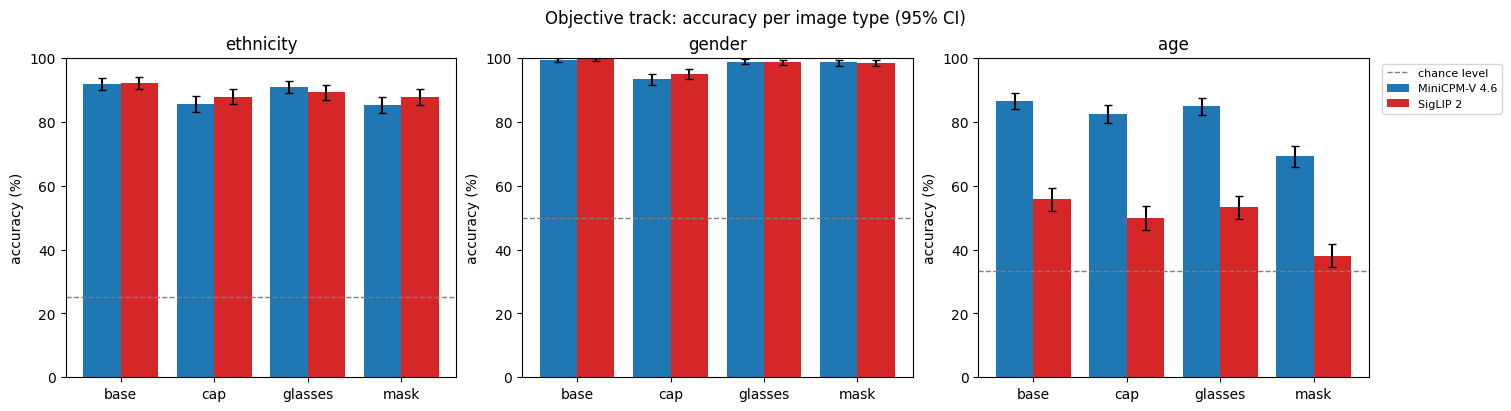

In [6]:

# [A2: accuracy per image type]
rows = []
for (model, attribute, image_type), g in obj.groupby(['model', 'item', 'image_type']):
    low, high = boot_ci(g['value'])
    rows.append({'model': model, 'attribute': attribute, 'image_type': image_type, 'n': len(g),
                 'accuracy': 100 * g['value'].mean(), 'ci_low': 100 * low, 'ci_high': 100 * high})
accuracy = rounded(pd.DataFrame(rows))
accuracy.to_csv(os.path.join(ANALYSIS_DIR, 'obj_accuracy.csv'), index=False)
display(accuracy.pivot(index=['model', 'attribute'], columns='image_type', values='accuracy')[IMAGE_TYPES])

fig, axes = plt.subplots(1, len(ATTRIBUTES), figsize=(15, 4), constrained_layout=True)
width = 0.8 / len(MODELS)
for ax, attribute in zip(axes, ATTRIBUTES):
    for k, model in enumerate(MODELS):
        a = (accuracy[(accuracy['model'] == model) & (accuracy['attribute'] == attribute)]
             .set_index('image_type').loc[IMAGE_TYPES])
        x = np.arange(len(IMAGE_TYPES)) + (k - (len(MODELS) - 1) / 2) * width
        ax.bar(x, a['accuracy'], width, yerr=err(a['accuracy'], a['ci_low'], a['ci_high']),
               capsize=3, color=MODEL_COLORS[model], label=model)
    ax.axhline(100 / len(OPTIONS[attribute]), color='grey', ls='--', lw=1, label='chance level')
    ax.set_xticks(range(len(IMAGE_TYPES)))
    ax.set_xticklabels(IMAGE_TYPES)
    ax.set_ylim(0, 100)
    ax.set_ylabel('accuracy (%)')
    ax.set_title(attribute)
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
fig.suptitle('Objective track: accuracy per image type (95% CI)')
savefig(fig, 'obj_accuracy.png')

## RQ1: effect of each accessory on accuracy
Paired over the 720 identities. acc_change_pts = accuracy with the accessory minus base accuracy (percentage points), with its 95% bootstrap CI (ci_low, ci_high). b = correct on base and wrong with the accessory, c = the reverse. p_value is the exact McNemar test of the track notebooks. In the figure, filled markers have p < 0.05.

,model,attribute,accessory,n,acc_base,acc_accessory,acc_change_pts,ci_low,ci_high,b_correct_to_wrong,c_wrong_to_correct,p_value
0,MiniCPM-V 4.6,ethnicity,cap,720,91.94,85.69,-6.25,-8.33,-4.31,51,6,5.676193e-10
1,MiniCPM-V 4.6,ethnicity,glasses,720,91.94,90.97,-0.97,-2.50,0.56,19,12,2.810415e-01
2,MiniCPM-V 4.6,ethnicity,mask,720,91.94,85.28,-6.67,-8.75,-4.86,52,4,1.100806e-11
3,MiniCPM-V 4.6,gender,cap,720,99.44,93.33,-6.11,-7.92,-4.44,44,0,1.136868e-13
4,MiniCPM-V 4.6,gender,glasses,720,99.44,98.89,-0.56,-1.11,-0.14,4,0,1.250000e-01
5,MiniCPM-V 4.6,gender,mask,720,99.44,98.61,-0.83,-1.67,-0.14,7,1,7.031250e-02
6,MiniCPM-V 4.6,age,cap,720,86.53,82.50,-4.03,-6.81,-1.39,64,35,4.640654e-03
7,MiniCPM-V 4.6,age,glasses,720,86.53,84.86,-1.67,-3.89,0.42,40,28,1.818101e-01
8,MiniCPM-V 4.6,age,mask,720,86.53,69.31,-17.22,-21.25,-13.06,184,60,7.904745e-16
9,SigLIP 2,ethnicity,cap,720,92.22,87.92,-4.31,-5.97,-2.78,33,2,3.672903e-08


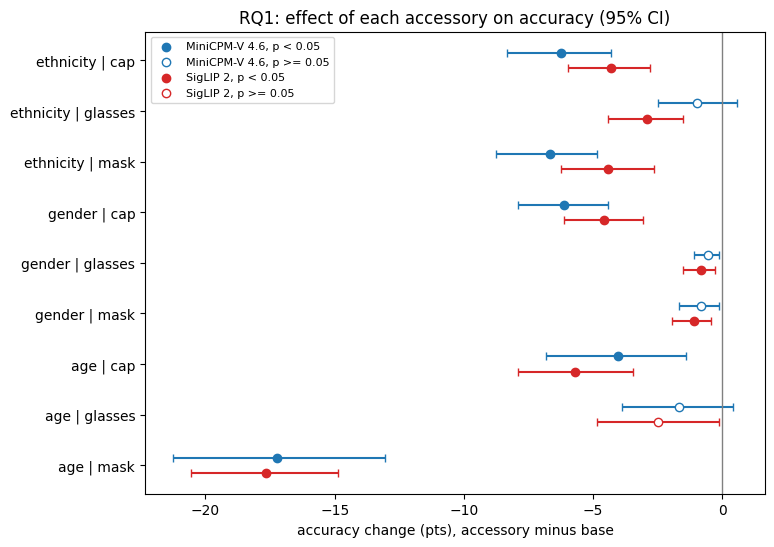

In [7]:
# [A3: RQ1]
def objective_view(t):
    t = t.rename(columns={'item': 'attribute', 'mean_base': 'acc_base', 'mean_accessory': 'acc_accessory',
                          'mean_change': 'acc_change_pts', 'n_down': 'b_correct_to_wrong',
                          'n_up': 'c_wrong_to_correct'})
    for c in ['acc_base', 'acc_accessory', 'acc_change_pts', 'ci_low', 'ci_high']:
        t[c] = 100 * t[c]
    # for a 0/1 outcome the net share equals the accuracy change
    return t.drop(columns=['n_same', 'net_share', 'net_ci_low', 'net_ci_high', 'n_excluded'], errors='ignore')

rq1 = rounded(objective_view(obj_effects))
rq1.to_csv(os.path.join(ANALYSIS_DIR, 'obj_rq1_effects.csv'), index=False)
display(rq1)
forest_plot(rq1, 'attribute', 'acc_change_pts', 'ci_low', 'ci_high',
            'accuracy change (pts), accessory minus base',
            'RQ1: effect of each accessory on accuracy (95% CI)', 'obj_rq1_forest.png')

## Direction of errors
Which way do the wrong answers go?
- Confusion matrices, one figure per model: rows are the true label, columns the answer, cells the % of the row. One column of panels per image type, so each accessory can be compared with base along the same row of panels.
- Age: mean signed error in years (answer minus true age, NONE left out), per true age and over all identities. Positive means the person is judged older.
- Gender: % of women answered as men and % of men answered as women.

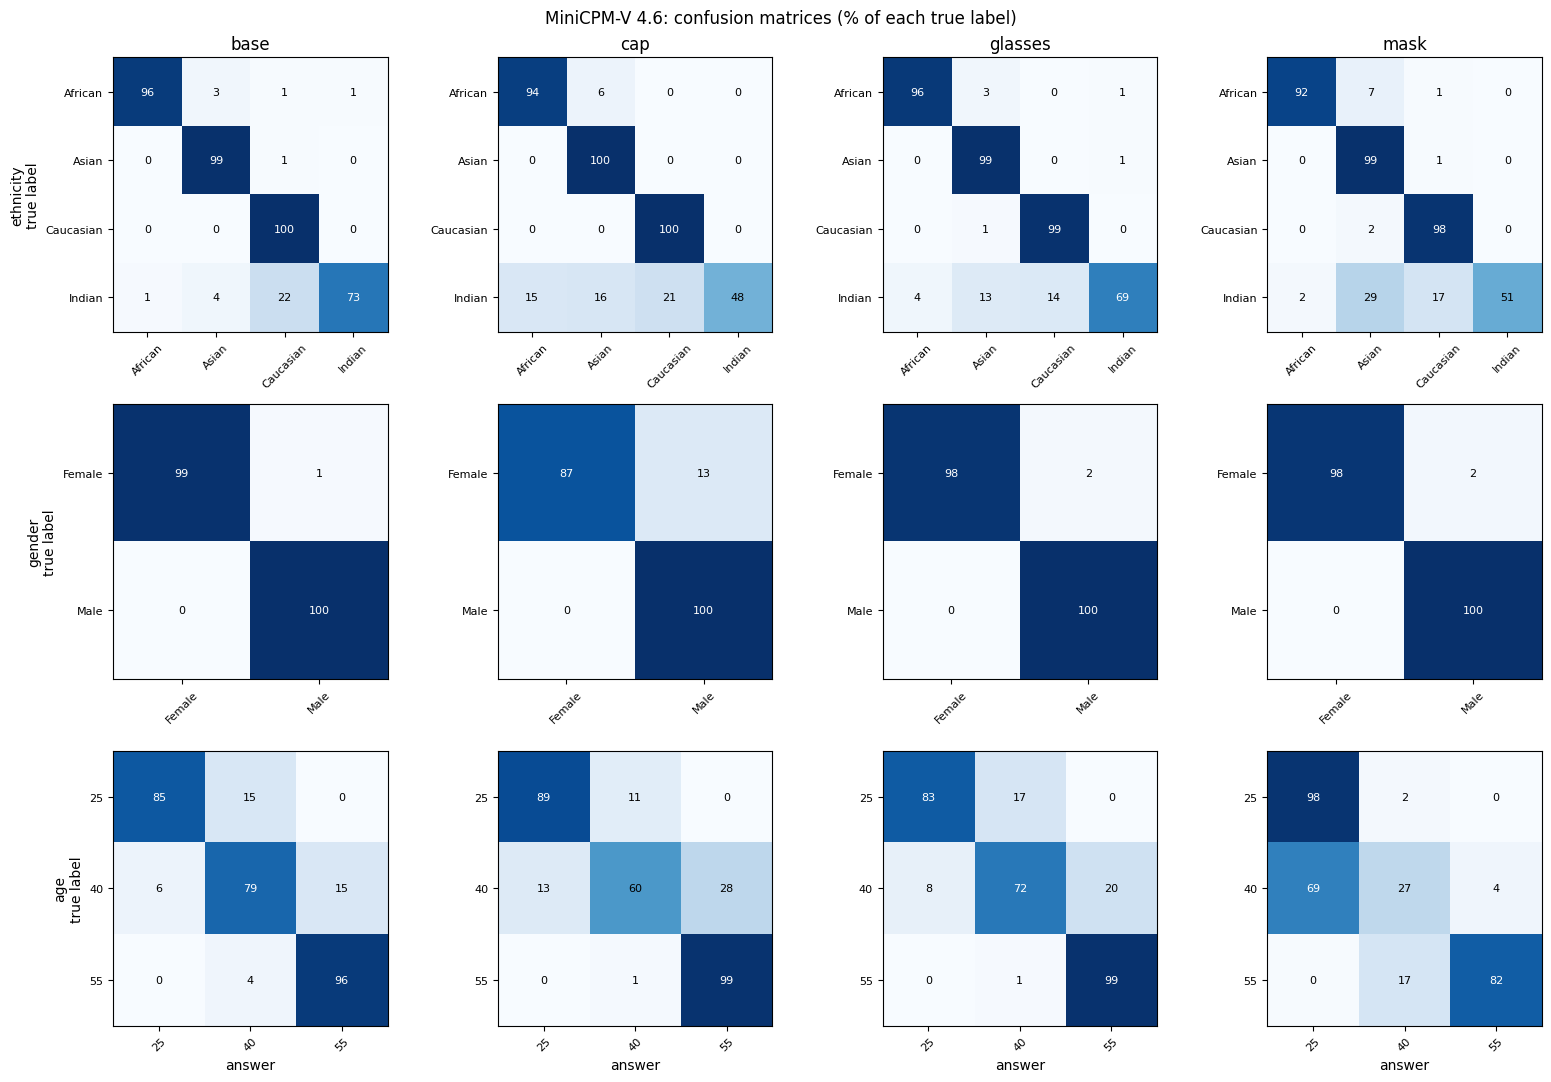

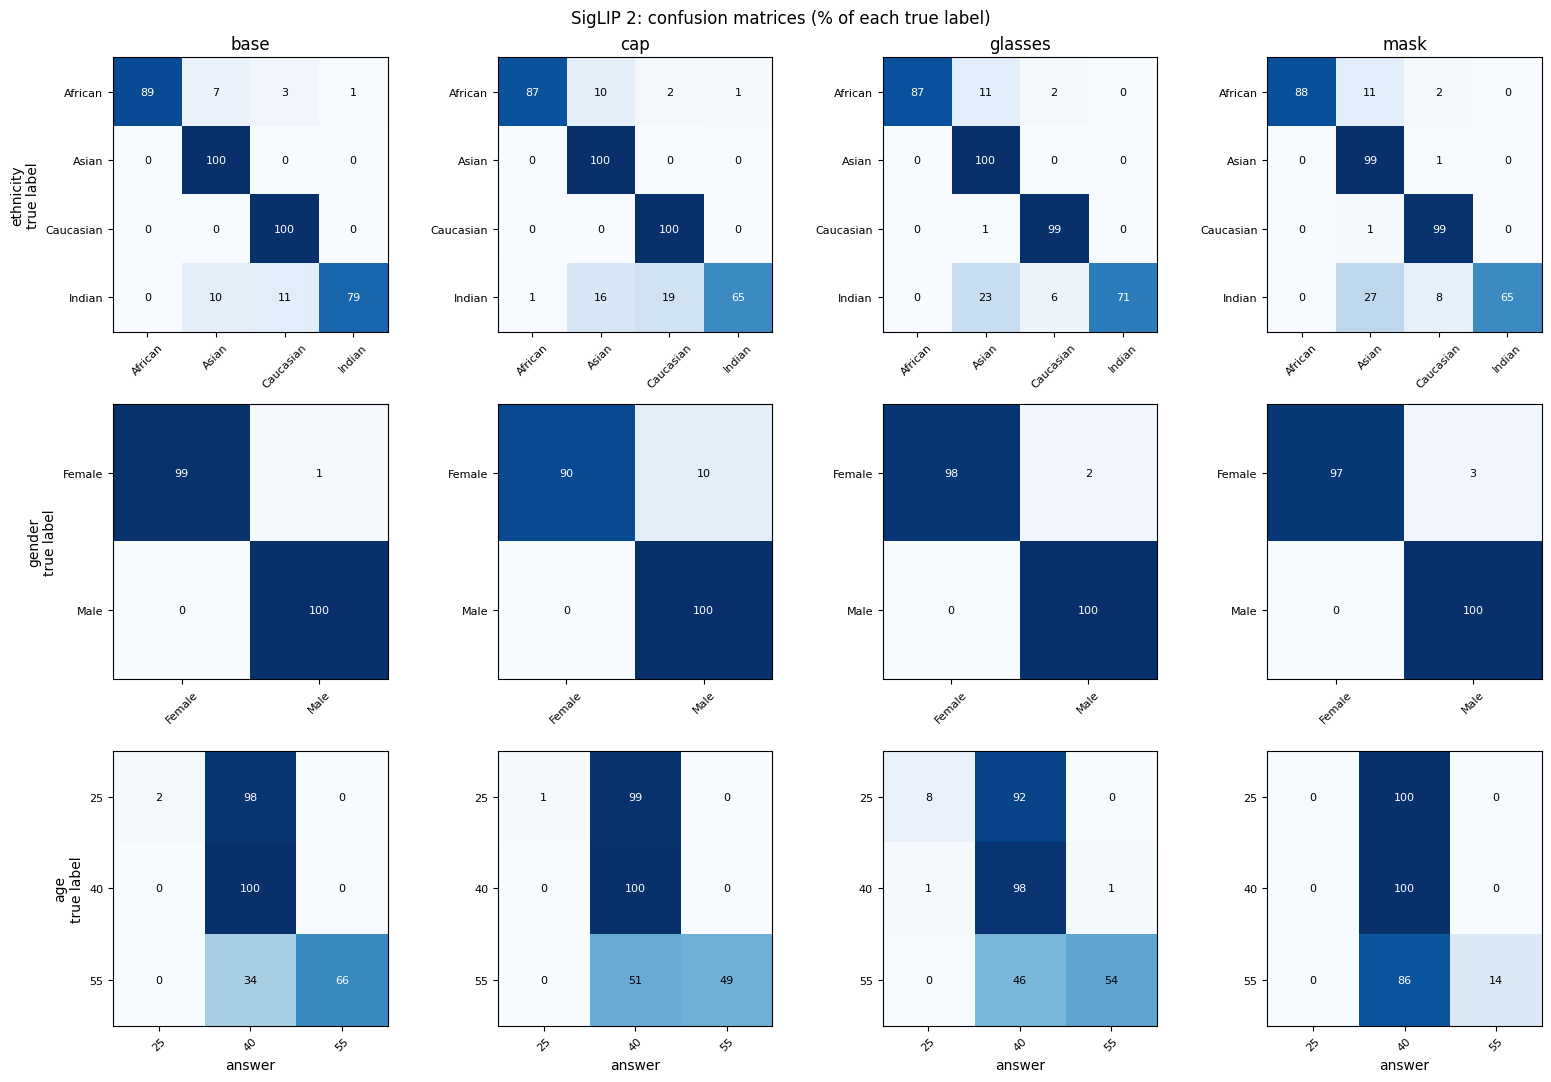

In [8]:
# [A4a: confusion matrices]
for model in MODELS:
    fig, axes = plt.subplots(len(ATTRIBUTES), len(IMAGE_TYPES), figsize=(16, 11))
    for r, attribute in enumerate(ATTRIBUTES):
        g_attr = obj[(obj['model'] == model) & (obj['item'] == attribute)]
        answers = OPTIONS[attribute] + (['NONE'] if g_attr['pred'].eq('NONE').any() else [])
        for c, image_type in enumerate(IMAGE_TYPES):
            g = g_attr[g_attr['image_type'] == image_type]
            counts = pd.crosstab(g['true_label'], g['pred']).reindex(
                index=OPTIONS[attribute], columns=answers, fill_value=0)
            pct = 100 * counts.div(counts.sum(axis=1), axis=0)
            ax = axes[r, c]
            ax.imshow(pct.values, cmap='Blues', vmin=0, vmax=100)
            for i in range(pct.shape[0]):
                for j in range(pct.shape[1]):
                    ax.text(j, i, f"{pct.iat[i, j]:.0f}", ha='center', va='center', fontsize=8,
                            color='white' if pct.iat[i, j] > 60 else 'black')
            ax.set_xticks(range(len(answers)))
            ax.set_xticklabels(answers, rotation=45, fontsize=8)
            ax.set_yticks(range(len(OPTIONS[attribute])))
            ax.set_yticklabels(OPTIONS[attribute], fontsize=8)
            if r == 0:
                ax.set_title(image_type)
            if c == 0:
                ax.set_ylabel(f"{attribute}\ntrue label")
            if r == len(ATTRIBUTES) - 1:
                ax.set_xlabel('answer')
    fig.suptitle(f"{model}: confusion matrices (% of each true label)")
    fig.tight_layout()
    savefig(fig, f"obj_confusion_{MODEL_TAG[model]}.png")

In [9]:
age = obj[(obj['item'] == 'age') & (obj['pred'] != 'NONE')].copy()
age['error'] = age['pred'].astype(int) - age['true_label'].astype(int)
age_error = (pd.concat([age, age.assign(true_label='all')])
             .groupby(['model', 'true_label', 'image_type'])['error'].mean()
             .unstack('image_type')[IMAGE_TYPES].round(2))
age_error.to_csv(os.path.join(ANALYSIS_DIR, 'obj_age_signed_error.csv'))
print("Age: mean signed error in years (answer minus true age), rows = true age:")
display(age_error)

gender = obj[obj['item'] == 'gender']
other = (gender['pred'] != gender['true_label']) & (gender['pred'] != 'NONE')
gender_flips = (gender.assign(other=other)
                .groupby(['model', 'true_label', 'image_type'])['other'].mean().mul(100)
                .unstack('image_type')[IMAGE_TYPES].round(2))
gender_flips.to_csv(os.path.join(ANALYSIS_DIR, 'obj_gender_flips.csv'))
print("Gender: % answered as the other gender, rows = true gender:")
display(gender_flips)

Age: mean signed error in years (answer minus true age), rows = true age:


image_type                 base    cap  glasses   mask
model         true_label                              
MiniCPM-V 4.6 25           2.31   1.62     2.50   0.25
              40           1.38   2.19     1.81  -9.69
              55          -0.62  -0.19    -0.12  -2.69
              all          1.02   1.21     1.40  -4.04
SigLIP 2      25          14.75  14.88    13.88  14.94
              40           0.06   0.00     0.06   0.00
              55          -5.12  -7.62    -6.88 -12.94
              all          3.23   2.42     2.35   0.67

Gender: % answered as the other gender, rows = true gender:


image_type                base    cap  glasses  mask
model         true_label                            
MiniCPM-V 4.6 Female      1.11  13.33     2.22  2.50
              Male        0.00   0.00     0.00  0.28
SigLIP 2      Female      0.83  10.00     2.50  3.06
              Male        0.00   0.00     0.00  0.00

## RQ3: groups (ethnicity, gender, age)
1. Base accuracy by group, and the Kruskal-Wallis p-value for "base accuracy differs between the groups". For a 0/1 outcome this is the chi-square test of homogeneity, up to a factor (N-1)/N.
2. Heatmap: accuracy change (pts) by group, for each attribute x accessory. * = p < 0.05 for the exact McNemar test inside the group (as in the by-group tables of the track notebooks).
3. Heterogeneity: Kruskal-Wallis test of the per-identity change (-1, 0 or +1) across the groups. A small p-value means the accessory changes accuracy differently across the groups. A significant effect in one group next to a non-significant effect in another is not, by itself, evidence of a difference between the groups.

Base accuracy (%) by group:


group_var               ETHNICITY                           GENDER          \
group                     African   Asian Caucasian  Indian Female    Male   
model         attribute                                                      
MiniCPM-V 4.6 age           83.89   86.11     86.67   89.44  86.11   86.94   
              ethnicity     95.56   99.44    100.00   72.78  92.78   91.11   
              gender        98.33   99.44    100.00  100.00  98.89  100.00   
SigLIP 2      age           62.22   58.89     45.56   56.11  56.67   54.72   
              ethnicity     89.44  100.00    100.00   79.44  90.83   93.61   
              gender        99.44   99.44     99.44  100.00  99.17  100.00   

group_var                  AGE                 
group                       25      40     55  
model         attribute                        
MiniCPM-V 4.6 age        84.58   79.17  95.83  
              ethnicity  92.92   92.92  90.00  
              gender     98.75  100.00  99.58  
SigLIP 2      age         1.67   99.58  65.83  
              ethnicity  92.92   93.75  90.00  
              gender     99.58  100.00  99.17

Kruskal-Wallis p-value, base accuracy differs between the groups:


group_var                   ETHNICITY    GENDER            AGE
model         attribute                                       
MiniCPM-V 4.6 age        4.907990e-01  0.743492   3.517181e-07
              ethnicity  3.290991e-26  0.411614   3.994888e-01
              gender     1.103935e-01  0.045050   1.725044e-01
SigLIP 2      age        9.984224e-03  0.599721  4.388519e-105
              ethnicity  8.945225e-16  0.164362   2.737526e-01
              gender     8.005770e-01  0.082836   3.668547e-01

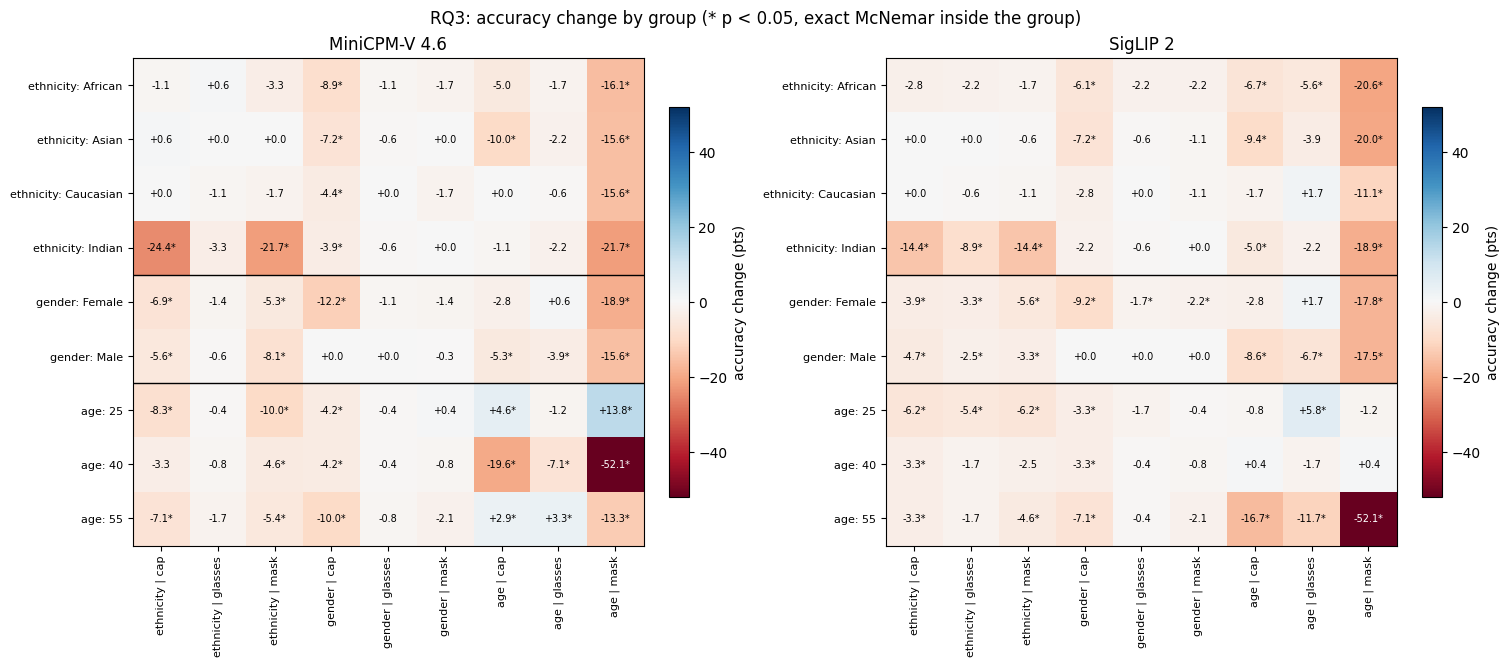

Kruskal-Wallis p-value, the accessory effect differs between the groups:


group_var                             ETHNICITY        GENDER           AGE
model         attribute accessory                                          
MiniCPM-V 4.6 age       cap        4.071133e-02  3.624880e-01  4.635138e-15
                        glasses    9.481766e-01  4.997121e-02  8.515199e-04
                        mask       6.845157e-01  4.402049e-01  9.541165e-41
              ethnicity cap        2.494785e-23  5.051134e-01  1.170145e-01
                        glasses    2.813458e-01  5.884226e-01  7.970889e-01
                        mask       1.761582e-16  1.725718e-01  6.402043e-02
              gender    cap        1.562877e-01  7.866090e-12  8.757045e-03
                        glasses    5.706693e-01  4.505019e-02  7.779854e-01
                        mask       2.083817e-01  1.549898e-01  3.373467e-02
SigLIP 2      age       cap        1.310679e-01  1.386386e-02  5.977436e-11
                        glasses    1.891801e-01  7.412988e-04  2.405642e-08
                        mask       6.789243e-02  9.091663e-01  1.826874e-63
              ethnicity cap        7.208987e-12  6.044254e-01  2.361774e-01
                        glasses    3.576305e-05  5.720418e-01  5.703050e-02
                        mask       4.470251e-09  2.175168e-01  2.415236e-01
              gender    cap        5.878073e-02  4.182001e-09  7.662158e-02
                        glasses    1.095838e-01  1.396932e-02  2.207986e-01
                        mask       2.572488e-01  4.478976e-03  1.937908e-01

In [10]:
obj_group, obj_het, obj_base = group_tables(obj, ATTRIBUTES)

base_acc = obj_base.assign(acc_base=100 * obj_base['mean_base']).rename(columns={'item': 'attribute'})
print("Base accuracy (%) by group:")
display(base_acc.set_index(['model', 'attribute', 'group_var', 'group'])['acc_base']
        .unstack(['group_var', 'group'])[GROUP_COLUMNS].round(2))
print("Kruskal-Wallis p-value, base accuracy differs between the groups:")
display(base_acc.drop_duplicates(['model', 'attribute', 'group_var'])
        .set_index(['model', 'attribute', 'group_var'])['kw_p'].unstack('group_var')[GROUP_VARS])

group_heatmap(obj_group, 'item', 'mean_change', 100, 'accuracy change (pts)',
              'RQ3: accuracy change by group (* p < 0.05, exact McNemar inside the group)', 'obj_rq3_heatmap.png')

obj_het = obj_het.rename(columns={'item': 'attribute'})
print("Kruskal-Wallis p-value, the accessory effect differs between the groups:")
display(obj_het.set_index(['model', 'attribute', 'accessory', 'group_var'])['kw_p']
        .unstack('group_var')[GROUP_VARS])

rounded(base_acc.drop(columns='mean_base')).to_csv(os.path.join(ANALYSIS_DIR, 'obj_base_by_group.csv'), index=False)
rounded(objective_view(obj_group)).to_csv(os.path.join(ANALYSIS_DIR, 'obj_rq3_by_group.csv'), index=False)
obj_het.to_csv(os.path.join(ANALYSIS_DIR, 'obj_rq3_heterogeneity.csv'), index=False)

# Part B. Subjective track (job fitness)

## Load the ratings and scores of both models
One row per model x identity x job x image type. value is the MiniCPM rating (1 = very unsuitable ... 5 = very suitable, NaN for NONE) or the SigLIP 2 job score (job logit minus neutral logit). The cell stops if a file is incomplete, or if the sign-test counts and p-values recomputed here differ from the tables saved by the track notebooks.

In [11]:
m = pd.read_csv(os.path.join(SUBJ_DIR, 'rated_results.csv'), dtype={'hash': str, 'final_letter': str})
m = m.assign(model='MiniCPM-V 4.6', value=m['rating'])
s = pd.read_csv(os.path.join(SUBJ_DIR, 'siglip2_job_scores.csv'), dtype={'hash': str})
s = s.assign(model='SigLIP 2', value=s['score'])

cols = ['model', 'hash', 'job', 'image_type', 'value', 'final_letter', 'job_logit', 'neutral_logit']
subj = (pd.concat([m.reindex(columns=cols), s.reindex(columns=cols)], ignore_index=True)
        .rename(columns={'job': 'item'}))

expected = N_ID * len(IMAGE_TYPES) * len(JOBS)
for model in MODELS:
    g = subj[subj['model'] == model]
    assert len(g) == expected, f"{model}: expected {expected} rows, found {len(g)}"
    assert not g.duplicated(['hash', 'item', 'image_type']).any(), f"{model}: duplicate rows"
    assert set(g['hash']) == set(labels.index), f"{model}: identities differ from the labels file"

mc = subj[subj['model'] == 'MiniCPM-V 4.6']
print("MiniCPM NONE answers (%, no rating):")
display((mc.assign(none=mc['value'].isna())
         .pivot_table(index='item', columns='image_type', values='none', aggfunc='mean')
         [IMAGE_TYPES] * 100).round(2))

subj_effects = effect_table(subj, JOBS)
saved_pairs = [('n', 'n_saved'), ('n_down', 'n_down_saved'), ('n_same', 'n_same_saved'), ('n_up', 'n_up_saved')]
check_saved(subj_effects, 'MiniCPM-V 4.6', os.path.join(SUBJ_DIR, 'sign_test_overall.csv'), 'job', saved_pairs)
check_saved(subj_effects, 'SigLIP 2', os.path.join(SUBJ_DIR, 'siglip2_sign_test_overall.csv'), 'job', saved_pairs)
print("sign-test counts and p-values match the track notebooks")

MiniCPM NONE answers (%, no rating):


image_type,base,cap,glasses,mask
item,,,,
construction_worker,0.0,0.0,0.0,0.0
nurse,0.0,0.0,0.0,0.0
software_engineer,0.0,0.0,0.0,0.0


sign-test counts and p-values match the track notebooks


## Ratings and scores per image type
- Mean value per job and image type (MiniCPM: rating 1 to 5; SigLIP 2: score in logit units).
- MiniCPM: share of each answer. When most base answers are already E (very suitable), a rating can almost only go down, so increases are hard to detect.
- SigLIP 2: distribution of the score. 0 means the image matches the job prompt as well as the neutral prompt "a person".
- SigLIP 2 check of the neutral-prompt subtraction: mean change of the score next to the mean change of the raw job logit and of the neutral logit (score change = job logit change minus neutral logit change). When the raw job logit and the score move in opposite directions, the raw change is mostly the accessory's general effect on every prompt about a person.

Mean value (MiniCPM: rating 1-5, SigLIP 2: score in logit units):


image_type                          base    cap  glasses   mask
model         job                                              
MiniCPM-V 4.6 software_engineer    4.874  4.940    4.983  4.958
              nurse                4.953  4.974    4.961  5.000
              construction_worker  4.938  4.989    4.962  4.789
SigLIP 2      software_engineer   -0.771 -0.536   -0.502 -2.928
              nurse               -3.213 -2.424   -3.077  0.104
              construction_worker -3.456 -1.552   -4.122 -3.761

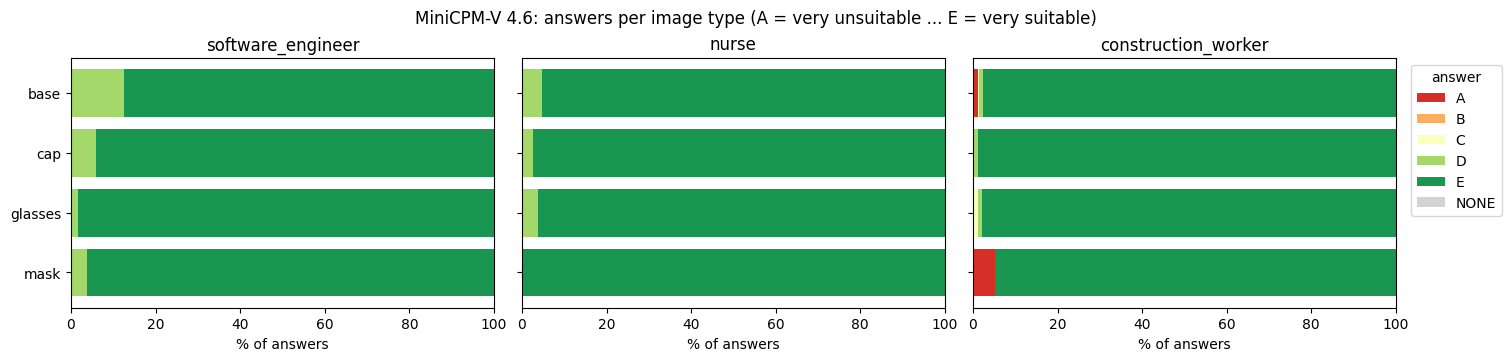

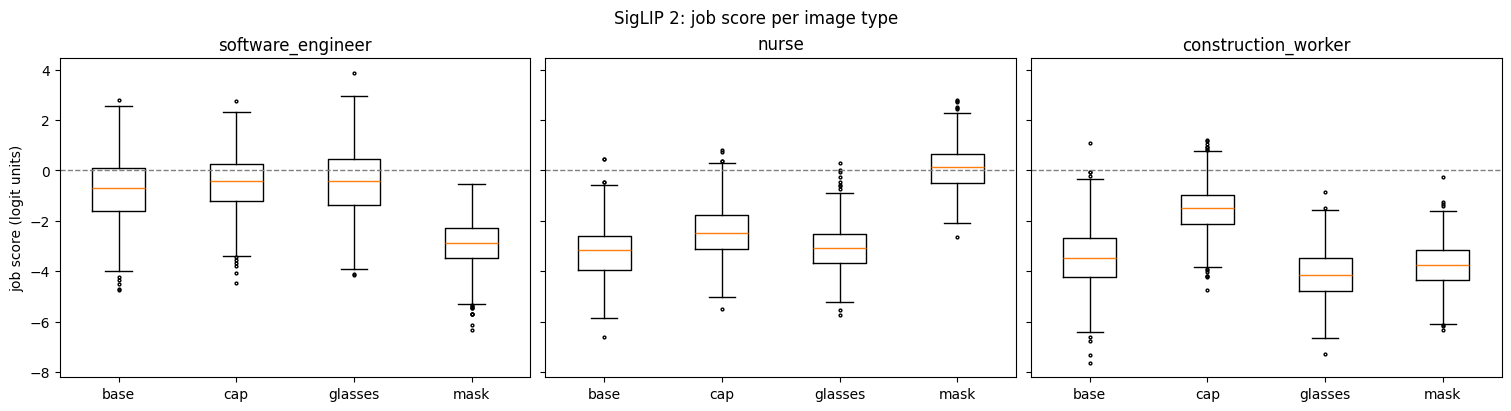

In [12]:
means = (subj.groupby(['model', 'item', 'image_type'])['value'].mean().unstack('image_type')[IMAGE_TYPES]
         .reindex(pd.MultiIndex.from_product([MODELS, JOBS], names=['model', 'job'])).round(3))
means.to_csv(os.path.join(ANALYSIS_DIR, 'subj_means.csv'))
print("Mean value (MiniCPM: rating 1-5, SigLIP 2: score in logit units):")
display(means)

answers = list('ABCDE') + ['NONE']
colors = list(plt.cm.RdYlGn(np.linspace(0.1, 0.9, 5))) + ['lightgrey']
fig, axes = plt.subplots(1, len(JOBS), figsize=(15, 3.5), sharey=True, constrained_layout=True)
for ax, job in zip(axes, JOBS):
    g = mc[mc['item'] == job]
    share = 100 * pd.crosstab(g['image_type'], g['final_letter'], normalize='index').reindex(
        index=IMAGE_TYPES, columns=answers, fill_value=0)
    left = np.zeros(len(IMAGE_TYPES))
    for answer, color in zip(answers, colors):
        ax.barh(IMAGE_TYPES, share[answer], left=left, color=color, label=answer)
        left += share[answer].values
    ax.set_xlim(0, 100)
    ax.set_xlabel('% of answers')
    ax.set_title(job)
axes[0].invert_yaxis()
axes[-1].legend(title='answer', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.suptitle('MiniCPM-V 4.6: answers per image type (A = very unsuitable ... E = very suitable)')
savefig(fig, 'subj_minicpm_answers.png')

sg = subj[subj['model'] == 'SigLIP 2']
fig, axes = plt.subplots(1, len(JOBS), figsize=(15, 4), sharey=True, constrained_layout=True)
for ax, job in zip(axes, JOBS):
    data = [sg.loc[(sg['item'] == job) & (sg['image_type'] == t), 'value'].values for t in IMAGE_TYPES]
    ax.boxplot(data, flierprops={'markersize': 2})
    ax.set_xticks(range(1, len(IMAGE_TYPES) + 1))
    ax.set_xticklabels(IMAGE_TYPES)
    ax.axhline(0, color='grey', ls='--', lw=1)
    ax.set_title(job)
axes[0].set_ylabel('job score (logit units)')
fig.suptitle('SigLIP 2: job score per image type')
savefig(fig, 'subj_siglip2_scores.png')

In [13]:
# [B2b: SigLIP 2, score vs raw job logit]
rows = []
for job in JOBS:
    g = sg[sg['item'] == job]
    for accessory in ACCESSORIES:
        row = {'job': job, 'accessory': accessory}
        for name, col in [('score', 'value'), ('job_logit', 'job_logit'), ('neutral_logit', 'neutral_logit')]:
            w = g.pivot(index='hash', columns='image_type', values=col)
            row[f"change_{name}"] = (w[accessory] - w['base']).mean()
        rows.append(row)
raw_check = pd.DataFrame(rows).round(3)
raw_check.to_csv(os.path.join(ANALYSIS_DIR, 'subj_siglip2_raw_logit_check.csv'), index=False)
display(raw_check)

,job,accessory,change_score,change_job_logit,change_neutral_logit
0,software_engineer,cap,0.235,-1.553,-1.788
1,software_engineer,glasses,0.268,-1.779,-2.048
2,software_engineer,mask,-2.158,-5.216,-3.058
3,nurse,cap,0.789,-0.999,-1.788
4,nurse,glasses,0.136,-1.911,-2.048
5,nurse,mask,3.316,0.258,-3.058
6,construction_worker,cap,1.904,0.116,-1.788
7,construction_worker,glasses,-0.666,-2.714,-2.048
8,construction_worker,mask,-0.306,-3.364,-3.058


## RQ2: effect of each accessory on job fitness
Paired over the identities with a value on both images. mean_change is in the model's own unit (MiniCPM: rating points; SigLIP 2: logit units), with its 95% bootstrap CI (ci_low, ci_high). net_pct = % of identities with a higher value with the accessory minus % with a lower value, with its 95% bootstrap CI. net_pct is on the same scale for both models and is what the sign test tests (p_value, as in the track notebooks). The figure shows net_pct; filled markers have p < 0.05.

,model,job,accessory,n,mean_base,mean_accessory,mean_change,ci_low,ci_high,n_down,n_same,n_up,net_pct,net_pct_ci_low,net_pct_ci_high,p_value,n_excluded
0,MiniCPM-V 4.6,software_engineer,cap,720,4.874,4.940,0.067,0.042,0.093,25,622,73,6.667,4.167,9.306,1.279606e-06,0
1,MiniCPM-V 4.6,software_engineer,glasses,720,4.874,4.983,0.110,0.086,0.135,5,631,84,10.972,8.611,13.472,1.423876e-19,0
2,MiniCPM-V 4.6,software_engineer,mask,720,4.874,4.958,0.085,0.056,0.114,20,616,84,8.889,6.250,11.667,1.638050e-10,0
3,MiniCPM-V 4.6,nurse,cap,720,4.953,4.974,0.021,0.003,0.039,16,673,31,2.083,0.278,3.889,3.998606e-02,0
4,MiniCPM-V 4.6,nurse,glasses,720,4.953,4.961,0.008,-0.010,0.026,21,672,27,0.833,-0.976,2.642,4.708790e-01,0
5,MiniCPM-V 4.6,nurse,mask,720,4.953,5.000,0.047,0.032,0.062,0,686,34,4.722,3.194,6.250,1.164153e-10,0
6,MiniCPM-V 4.6,construction_worker,cap,720,4.938,4.989,0.051,0.018,0.088,8,695,17,1.250,-0.139,2.639,1.077521e-01,0
7,MiniCPM-V 4.6,construction_worker,glasses,720,4.938,4.962,0.025,-0.011,0.062,13,690,17,0.556,-0.972,2.083,5.846647e-01,0
8,MiniCPM-V 4.6,construction_worker,mask,720,4.938,4.789,-0.149,-0.217,-0.085,34,674,12,-3.056,-4.861,-1.250,1.641491e-03,0
9,SigLIP 2,software_engineer,cap,720,-0.771,-0.536,0.235,0.179,0.293,275,0,445,23.611,16.667,30.556,2.499373e-10,0


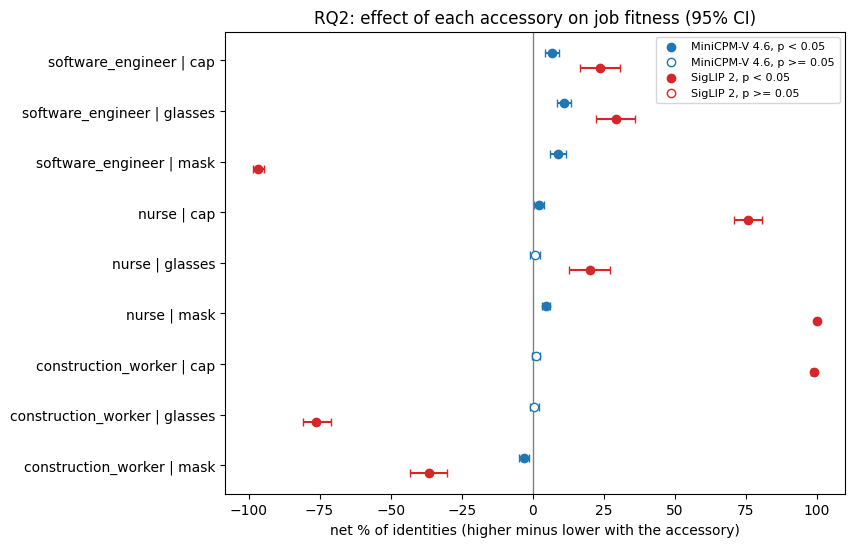

In [14]:
# [B3: RQ2]
def subjective_view(t):
    t = t.rename(columns={'item': 'job', 'net_share': 'net_pct', 'net_ci_low': 'net_pct_ci_low',
                          'net_ci_high': 'net_pct_ci_high'})
    for c in ['net_pct', 'net_pct_ci_low', 'net_pct_ci_high']:
        t[c] = 100 * t[c]
    return t

rq2 = rounded(subjective_view(subj_effects), 3)
rq2.to_csv(os.path.join(ANALYSIS_DIR, 'subj_rq2_effects.csv'), index=False)
display(rq2)
forest_plot(rq2, 'job', 'net_pct', 'net_pct_ci_low', 'net_pct_ci_high',
            'net % of identities (higher minus lower with the accessory)',
            'RQ2: effect of each accessory on job fitness (95% CI)', 'subj_rq2_forest.png')

## Stereotype congruence (extra analysis)
The jobs were chosen so that each accessory has a stereotype link to one job: glasses → software engineer, mask → nurse, cap → construction worker. For each identity and accessory: contrast = change of the linked job minus the mean change of the other two jobs. A positive mean_contrast means the accessory raises the linked job more than the other two. Exact sign test on the contrast (n_down / n_up = identities with a negative / positive contrast), 95% bootstrap CI. Identities with a NONE answer on any of the 6 image x job cells involved are left out.

In [15]:
rows = []
for model in MODELS:
    w = {job: wide(subj, model, job) for job in JOBS}
    for accessory, linked in LINKED_JOB.items():
        others = [job for job in JOBS if job != linked]
        change = pd.DataFrame({job: w[job][accessory] - w[job]['base'] for job in JOBS}).dropna()
        contrast = change[linked] - change[others].mean(axis=1)
        n_down, n_up = int((contrast < 0).sum()), int((contrast > 0).sum())
        ci_low, ci_high = boot_ci(contrast)
        rows.append({'model': model, 'accessory': accessory, 'linked_job': linked, 'n': len(contrast),
                     'change_linked': change[linked].mean(), 'change_others': change[others].values.mean(),
                     'mean_contrast': contrast.mean(), 'ci_low': ci_low, 'ci_high': ci_high,
                     'n_down': n_down, 'n_same': len(contrast) - n_down - n_up, 'n_up': n_up,
                     'p_value': exact_p(n_down, n_up)})
congruence = rounded(pd.DataFrame(rows), 3)
congruence.to_csv(os.path.join(ANALYSIS_DIR, 'subj_congruence.csv'), index=False)
display(congruence)

,model,accessory,linked_job,n,change_linked,change_others,mean_contrast,ci_low,ci_high,n_down,n_same,n_up,p_value
0,MiniCPM-V 4.6,glasses,software_engineer,720,0.110,0.017,0.093,0.061,0.126,36,577,107,2.253384e-09
1,MiniCPM-V 4.6,mask,nurse,720,0.047,-0.032,0.079,0.041,0.119,83,552,85,9.385334e-01
2,MiniCPM-V 4.6,cap,construction_worker,720,0.051,0.044,0.008,-0.029,0.049,94,578,48,1.407629e-04
3,SigLIP 2,glasses,software_engineer,720,0.268,-0.265,0.534,0.501,0.566,80,0,640,2.337237e-109
4,SigLIP 2,mask,nurse,720,3.316,-1.232,4.548,4.498,4.598,0,0,720,3.626044e-217
5,SigLIP 2,cap,construction_worker,720,1.904,0.512,1.392,1.360,1.425,7,0,713,7.077788e-201


## RQ3: groups (ethnicity, gender, age)
1. Base value by group (MiniCPM mean rating, SigLIP 2 mean score) and the Kruskal-Wallis p-value for "the groups differ on base images". This is the demographic bias of each model before any accessory.
2. Heatmap: net % (higher minus lower) by group, for each job x accessory. * = p < 0.05 for the exact sign test inside the group (as in the by-group tables of the track notebooks).
3. Heterogeneity: Kruskal-Wallis test of the per-identity change across the groups. A small p-value means the accessory changes job fitness differently across the groups.

Base value by group (MiniCPM: mean rating, SigLIP 2: mean score):


group_var                         ETHNICITY                         GENDER  \
group                               African  Asian Caucasian Indian Female   
model         job                                                            
MiniCPM-V 4.6 construction_worker     4.933  4.944     4.967  4.906  4.897   
              nurse                   4.994  4.967     4.933  4.917  5.000   
              software_engineer       4.967  4.883     4.822  4.822  4.953   
SigLIP 2      construction_worker    -3.502 -3.137    -3.878 -3.306 -4.181   
              nurse                  -3.221 -3.196    -3.182 -3.252 -2.805   
              software_engineer      -1.284 -0.662    -0.643 -0.494 -1.196   

group_var                                   AGE                
group                               Male     25     40     55  
model         job                                              
MiniCPM-V 4.6 construction_worker  4.978  4.904  4.950  4.958  
              nurse                4.906  4.975  4.954  4.929  
              software_engineer    4.794  4.962  4.879  4.779  
SigLIP 2      construction_worker -2.730 -3.086 -3.294 -3.987  
              nurse               -3.621 -2.855 -3.160 -3.624  
              software_engineer   -0.346  0.006 -0.454 -1.864

Kruskal-Wallis p-value, base value differs between the groups:


group_var                             ETHNICITY        GENDER           AGE
model         job                                                          
MiniCPM-V 4.6 construction_worker  4.640299e-01  8.209915e-02  7.802890e-02
              nurse                2.378119e-03  2.379038e-09  6.049333e-02
              software_engineer    4.341530e-05  1.676113e-10  1.140347e-08
SigLIP 2      construction_worker  1.773277e-08  1.380274e-66  6.496715e-16
              nurse                8.687855e-01  3.369091e-28  1.131557e-15
              software_engineer    3.276413e-07  3.417085e-19  2.137187e-64

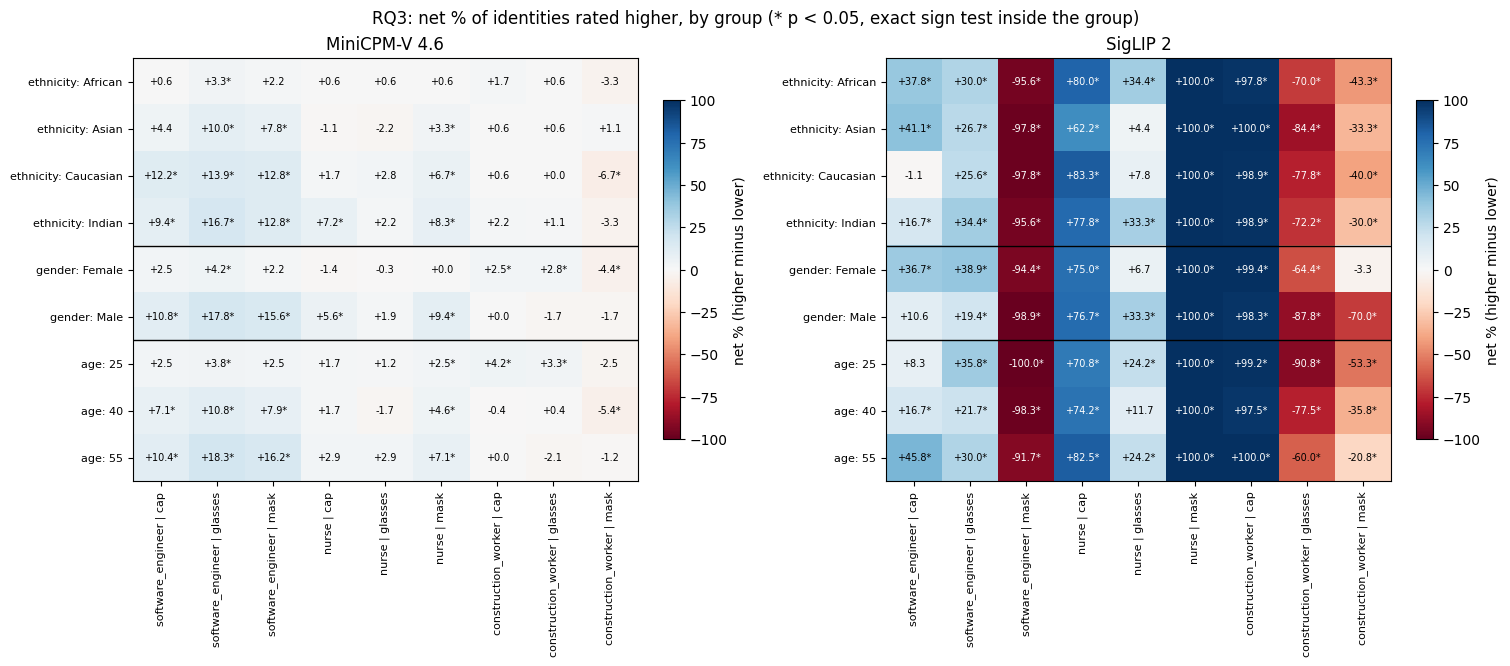

Kruskal-Wallis p-value, the accessory effect differs between the groups:


group_var                                    ETHNICITY        GENDER  \
model         job                 accessory                            
MiniCPM-V 4.6 construction_worker cap         0.777296  6.828393e-02   
                                  glasses     0.965959  3.351948e-03   
                                  mask        0.030768  1.346700e-01   
              nurse               cap         0.012232  2.135852e-04   
                                  glasses     0.250465  2.370041e-01   
                                  mask        0.002378  2.379038e-09   
              software_engineer   cap         0.009650  1.290156e-03   
                                  glasses     0.000884  3.015490e-08   
                                  mask        0.012656  6.704728e-07   
SigLIP 2      construction_worker cap         0.089268  2.066734e-22   
                                  glasses     0.600855  1.188360e-11   
                                  mask        0.108411  1.074830e-27   
              nurse               cap         0.001317  8.363897e-05   
                                  glasses     0.000087  2.216189e-05   
                                  mask        0.007490  4.645108e-06   
              software_engineer   cap         0.000003  5.199881e-06   
                                  glasses     0.233500  1.556342e-03   
                                  mask        0.000543  1.157005e-16   

group_var                                             AGE  
model         job                 accessory                
MiniCPM-V 4.6 construction_worker cap        1.216246e-02  
                                  glasses    1.511032e-02  
                                  mask       1.745825e-01  
              nurse               cap        8.097614e-01  
                                  glasses    1.450635e-01  
                                  mask       6.049333e-02  
              software_engineer   cap        3.884867e-02  
                                  glasses    6.359768e-06  
                                  mask       1.135343e-04  
SigLIP 2      construction_worker cap        7.998532e-07  
                                  glasses    8.518377e-11  
                                  mask       1.660439e-07  
              nurse               cap        8.091345e-03  
                                  glasses    2.760648e-01  
                                  mask       1.572149e-01  
              software_engineer   cap        9.801772e-10  
                                  glasses    7.127557e-01  
                                  mask       2.347290e-29

In [16]:
subj_group, subj_het, subj_base = group_tables(subj, JOBS)

base_val = subj_base.rename(columns={'item': 'job'})
print("Base value by group (MiniCPM: mean rating, SigLIP 2: mean score):")
display(base_val.set_index(['model', 'job', 'group_var', 'group'])['mean_base']
        .unstack(['group_var', 'group'])[GROUP_COLUMNS].round(3))
print("Kruskal-Wallis p-value, base value differs between the groups:")
display(base_val.drop_duplicates(['model', 'job', 'group_var'])
        .set_index(['model', 'job', 'group_var'])['kw_p'].unstack('group_var')[GROUP_VARS])

group_heatmap(subj_group, 'item', 'net_share', 100, 'net % (higher minus lower)',
              'RQ3: net % of identities rated higher, by group (* p < 0.05, exact sign test inside the group)',
              'subj_rq3_heatmap.png')

subj_het = subj_het.rename(columns={'item': 'job'})
print("Kruskal-Wallis p-value, the accessory effect differs between the groups:")
display(subj_het.set_index(['model', 'job', 'accessory', 'group_var'])['kw_p']
        .unstack('group_var')[GROUP_VARS])

rounded(base_val, 3).to_csv(os.path.join(ANALYSIS_DIR, 'subj_base_by_group.csv'), index=False)
rounded(subjective_view(subj_group), 3).to_csv(os.path.join(ANALYSIS_DIR, 'subj_rq3_by_group.csv'), index=False)
subj_het.to_csv(os.path.join(ANALYSIS_DIR, 'subj_rq3_heterogeneity.csv'), index=False)

## Output files'names

In [18]:
for name in sorted(os.listdir(ANALYSIS_DIR)):
    print(name)

obj_accuracy.csv
obj_accuracy.png
obj_age_signed_error.csv
obj_base_by_group.csv
obj_confusion_minicpm.png
obj_confusion_siglip2.png
obj_gender_flips.csv
obj_rq1_effects.csv
obj_rq1_forest.png
obj_rq3_by_group.csv
obj_rq3_heatmap.png
obj_rq3_heterogeneity.csv
subj_base_by_group.csv
subj_congruence.csv
subj_means.csv
subj_minicpm_answers.png
subj_rq2_effects.csv
subj_rq2_forest.png
subj_rq3_by_group.csv
subj_rq3_heatmap.png
subj_rq3_heterogeneity.csv
subj_siglip2_raw_logit_check.csv
subj_siglip2_scores.png
